# IRIS classification: photonic KAN with field encoding (√m version)

Direct classifier [4, 3], strictly positive expansion coefficients, no affine map.

**Field-encoding edge model** (update after IPC 2026). For an edge with $m$ photonic bases:

1. $u = \alpha x + \beta$ (affine map), or $u = x$ if no affine map is needed
2. $u/\sqrt{m}$ — 1:$m$ splitter
3. $P = u^2/m$ — optical power entering each FP-LD
4. $b_k(P)$ — analytic FP-LD activation (log/exp/polynomial fit)
5. $\sqrt{b_k(P)}$ — output field amplitude of basis $k$
6. $a_k \sqrt{b_k(P)}$ — expansion coefficient
7. $\varphi(x) = \sum_k a_k \sqrt{b_k(u^2/m)}$; edges are summed at the next node

The input range is chosen so that $P$ covers the same **power window** $[P_{\min}, P_{\max}]$ the bases saw in the May runs,
i.e. $u \in [\sqrt{m P_{\min}}, \sqrt{m P_{\max}}]$. Because every edge has the same $m$, the $1/\sqrt{m}$ factor is absorbed by this choice:
`DIVIDE_BY_M = False` gives identical results.

## Imports

In [13]:
import os

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
from scipy.io import savemat, loadmat

import importlib
import kan

importlib.reload(kan)

<module 'kan' from '/Users/sofijaorlovic/Desktop/sofka/Kolmogorov-Arnold Networks (KAN) - diplomski/photonic-KAN/kan.py'>

## Settings

Only the photonic part differs from the May run (`iris_experiment.ipynb`). Basis selection, split, optimizer and learning rate are unchanged. Differences: 6000 epochs instead of 3000, and a fixed seed for the coefficient initialisation (the May run was unseeded).

In [14]:
# Photonic bases (same as May / IPC 2026)
selected_indices = np.array([1, 3, 7])
m = len(selected_indices)            # bases per edge

# Power window seen by the FP-LD: P = x^2/m in [P_MIN, P_MAX]
# (May: the bases were evaluated directly on x in [0, 1])
P_MIN, P_MAX = 0.0, 1.0
DIVIDE_BY_M = True                   # 1:m splitter; False gives identical results

# Input amplitude range that fills the power window: x in [sqrt(m*P_MIN), sqrt(m*P_MAX)]
x_min_physical, x_max_physical = kan.amplitude_window_from_power_window(P_MIN, P_MAX, m, DIVIDE_BY_M)

SEED = 42
epochs = 6000   # May: 3000. Test runs: 3000 epochs -> 94.74 %, 6000 epochs -> 97.37 %
               # (with sqrt(b) the logits are smaller and training converges more slowly)
lr = 1e-3

mat_folder = "kan_iris_positive_sqrtm_export"
os.makedirs(mat_folder, exist_ok=True)

print(f"m = {m}")
print(f"Power window P = [{P_MIN}, {P_MAX}]  ->  input amplitude x in [{x_min_physical:.6f}, {x_max_physical:.6f}]")

m = 3
Power window P = [0.0, 1.0]  ->  input amplitude x in [0.000000, 1.732051]


## Load photonic activation

In [15]:
mat_path = "activation_KAN_fit_B_Sofija_extend_positive_basisKAN.mat"

b_coef, input_power, peakout_data, set_detuning = kan.load_photonic_activation_data(mat_path)
b_coef_selected = b_coef[selected_indices]

print("Selected indices:", selected_indices)
print("Selected detunings:", set_detuning[selected_indices])
print("Selected b_coef shape:", b_coef_selected.shape)
print("input_power range of the fit:", input_power.min().item(), "-", input_power.max().item())

Selected indices: [1 3 7]
Selected detunings: tensor([-6.0000e+10, -8.0000e+10, -1.2000e+11])
Selected b_coef shape: torch.Size([3, 8])
input_power range of the fit: 0.0 - 60.0


## Load Iris data, split, scale

Features are min-max scaled to the input amplitude range $[0, \sqrt{m P_{\max}}]$ instead of $[0, 1]$, fitted on the training set only and clipped to that range (as in May).

In [16]:
iris = load_iris()
X = iris.data
y = iris.target

X_train_original, X_test_original, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y,
)

# Min-max scaling fitted on the TRAINING set only, then clipped to the input window (as in May).
# Clipping is part of the data preparation, not of the network: it models the finite drive range of the
# input modulator. It never changes training values (they lie inside by construction); in this split it
# changes one test value (petal length, -0.03 -> 0).
scaler = MinMaxScaler(feature_range=(x_min_physical, x_max_physical))

X_train_scaled = scaler.fit_transform(X_train_original)
X_test_scaled = scaler.transform(X_test_original)

n_clipped_test = int(((X_test_scaled < x_min_physical) | (X_test_scaled > x_max_physical)).sum())
X_train_scaled = np.clip(X_train_scaled, x_min_physical, x_max_physical)
X_test_scaled = np.clip(X_test_scaled, x_min_physical, x_max_physical)
print("Test values clipped:", n_clipped_test)

print("X_train_scaled min/max:", X_train_scaled.min(), X_train_scaled.max())
print("X_test_scaled  min/max:", X_test_scaled.min(), X_test_scaled.max())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

Test values clipped: 1
X_train_scaled min/max: 0.0 1.7320508075688772
X_test_scaled  min/max: 0.0 1.659882023920174
Using device: cpu


## KAN model

In [17]:
torch.manual_seed(SEED)

model = kan.KAN(
    in_count=4,
    out_count=3,
    hidden_layer_sizes=[],
    layer_type="photonic_positive",
    b_coef_selected=b_coef_selected,
    x_min=x_min_physical,
    x_max=x_max_physical,
    dropout_prob=0.0,
    normalize_basis=False,
    check_input_range=True,
    debug=False,
    coeff_eps=1e-9,
    field_encoding=True,
    divide_by_m=DIVIDE_BY_M,
).to(device)

print(model)

# Range check of the photonic chain before training
with torch.no_grad():
    _, stats = model(X_train_t, track_stats=True)
s = stats[0]
print(f"x  in [{s['min_input'].item():.4f}, {s['max_input'].item():.4f}]")
print(f"P  in [{s['min_P'].item():.4f}, {s['max_P'].item():.4f}]   (FP-LD input power)")
print(f"b  in [{s['min_b'].item():.4f}, {s['max_b'].item():.4f}]")
print(f"sqrt(b) in [{s['min_basis'].item():.4f}, {s['max_basis'].item():.4f}]")

KAN(
  (layers): ModuleList(
    (0): PhotonicBasisActivationLayerPositive()
  )
)
x  in [0.0000, 1.7321]
P  in [0.0000, 1.0000]   (FP-LD input power)
b  in [0.0000, 5.7438]
sqrt(b) in [0.0000, 2.3966]


## Training

In [18]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    train_logits = model(X_train_t)
    train_loss = loss_fn(train_logits, y_train_t)
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        train_logits_eval = model(X_train_t)
        train_loss_eval = loss_fn(train_logits_eval, y_train_t)
        train_acc = (train_logits_eval.argmax(dim=1) == y_train_t).float().mean().item()

        test_logits = model(X_test_t)
        test_loss = loss_fn(test_logits, y_test_t)
        test_acc = (test_logits.argmax(dim=1) == y_test_t).float().mean().item()

    train_loss_history.append(train_loss_eval.item())
    test_loss_history.append(test_loss.item())
    train_acc_history.append(train_acc)
    test_acc_history.append(test_acc)

    if epoch % 100 == 0 or epoch == epochs - 1:
        print(
            f"Epoch {epoch:4d} | Train loss: {train_loss_eval.item():.6f} | "
            f"Test loss: {test_loss.item():.6f} | Train acc: {train_acc:.4f} | Test acc: {test_acc:.4f}"
        )

Epoch    0 | Train loss: 1.106326 | Test loss: 1.106018 | Train acc: 0.0179 | Test acc: 0.0000
Epoch  100 | Train loss: 0.863483 | Test loss: 0.887138 | Train acc: 0.6696 | Test acc: 0.6579
Epoch  200 | Train loss: 0.719921 | Test loss: 0.758483 | Train acc: 0.8125 | Test acc: 0.7895
Epoch  300 | Train loss: 0.619753 | Test loss: 0.669489 | Train acc: 0.9196 | Test acc: 0.9474
Epoch  400 | Train loss: 0.544000 | Test loss: 0.602387 | Train acc: 0.9554 | Test acc: 0.9737
Epoch  500 | Train loss: 0.484396 | Test loss: 0.549263 | Train acc: 0.9643 | Test acc: 0.9737
Epoch  600 | Train loss: 0.436332 | Test loss: 0.505862 | Train acc: 0.9732 | Test acc: 0.9474
Epoch  700 | Train loss: 0.396841 | Test loss: 0.469623 | Train acc: 0.9732 | Test acc: 0.9474
Epoch  800 | Train loss: 0.363871 | Test loss: 0.438867 | Train acc: 0.9732 | Test acc: 0.9474
Epoch  900 | Train loss: 0.335953 | Test loss: 0.412414 | Train acc: 0.9821 | Test acc: 0.9474
Epoch 1000 | Train loss: 0.312007 | Test loss: 0.3

## Loss and accuracy curves

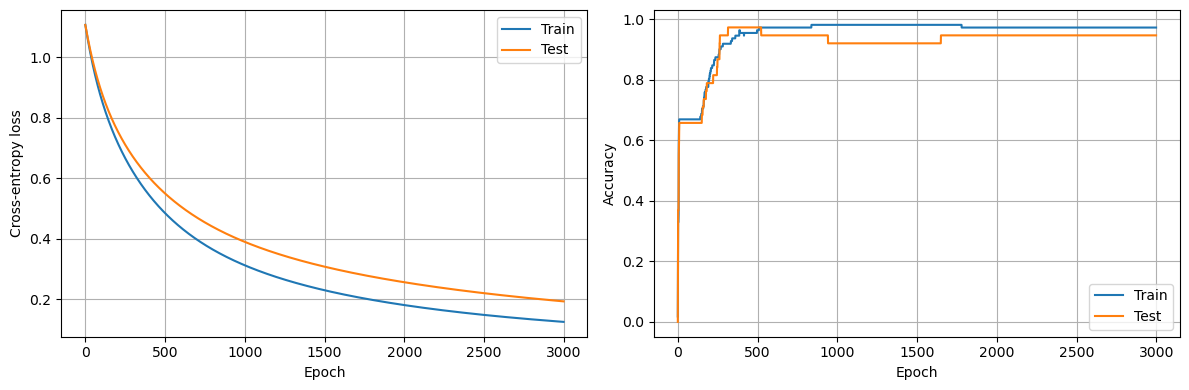

In [19]:
savemat(os.path.join(mat_folder, "loss_curves.mat"), {
    "plot_type": "loss_curves",
    "epoch": np.arange(epochs),
    "train_losses": np.array(train_loss_history),
    "test_losses": np.array(test_loss_history),
    "num_epochs": epochs,
})
savemat(os.path.join(mat_folder, "accuracy_curves.mat"), {
    "plot_type": "accuracy_curves",
    "epoch": np.arange(epochs),
    "train_accuracies": np.array(train_acc_history),
    "test_accuracies": np.array(test_acc_history),
    "num_epochs": epochs,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_loss_history, label="Train"); axes[0].plot(test_loss_history, label="Test")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss"); axes[0].grid(True); axes[0].legend()
axes[1].plot(train_acc_history, label="Train"); axes[1].plot(test_acc_history, label="Test")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].grid(True); axes[1].legend()
plt.tight_layout(); plt.show()

## Final predictions

In [20]:
model.eval()
with torch.no_grad():
    train_logits = model(X_train_t)
    test_logits = model(X_test_t)
train_pred = train_logits.argmax(dim=1)
test_pred = test_logits.argmax(dim=1)
train_acc = (train_pred == y_train_t).float().mean().item()
test_acc = (test_pred == y_test_t).float().mean().item()

savemat(os.path.join(mat_folder, "final_predictions.mat"), {
    "plot_type": "final_predictions",
    "y_test": y_test_t.cpu().numpy(),
    "test_pred": test_pred.cpu().numpy(),
    "y_train": y_train_t.cpu().numpy(),
    "train_pred": train_pred.cpu().numpy(),
})

print("Train accuracy:", train_acc)
print("Test accuracy: ", test_acc)
print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_pred.cpu().numpy()))
print("\nClassification report:")
print(classification_report(y_test, test_pred.cpu().numpy(), target_names=iris.target_names))

sorted_logits, _ = torch.sort(test_logits, dim=1, descending=True)
margins = sorted_logits[:, 0] - sorted_logits[:, 1]
coeffs_eff = model.layers[0].get_coeffs().detach()
print(f"Logits in [{test_logits.min().item():.4f}, {test_logits.max().item():.4f}]")
print(f"Margin min/mean/max: {margins.min().item():.4f} / {margins.mean().item():.4f} / {margins.max().item():.4f}")
print(f"Coefficients a min/mean/max: {coeffs_eff.min().item():.4f} / {coeffs_eff.mean().item():.4f} / {coeffs_eff.max().item():.4f}")

Train accuracy: 0.9732142686843872
Test accuracy:  0.9473684430122375

Confusion matrix:
[[12  0  0]
 [ 0 12  1]
 [ 0  1 12]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38

Logits in [0.1084, 21.1929]
Margin min/mean/max: 0.0297 / 2.5139 / 5.8493
Coefficients a min/mean/max: 0.1276 / 0.8451 / 2.1399


## Edge and basis functions

The basis plotted against $x$ is the effective basis $\sqrt{b_k(x^2/m)}$. The `.mat` files also contain `P` (= $x^2/m$) and `b_raw` (= $b_k(P)$).

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out0_in0.mat


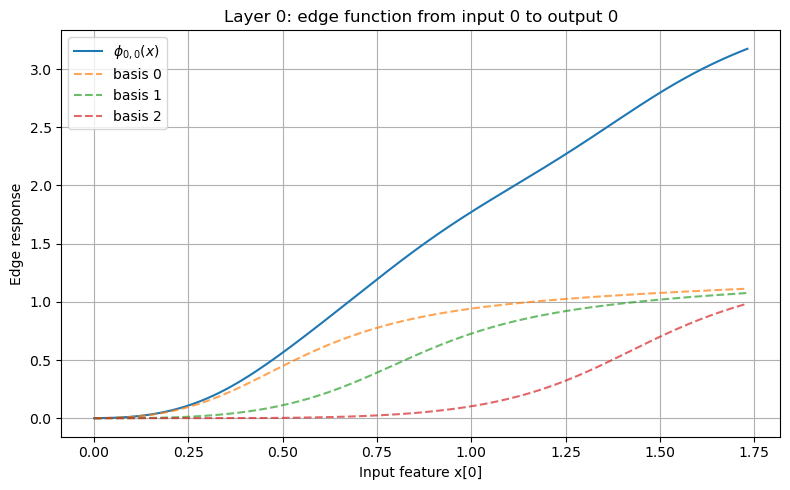

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out1_in0.mat


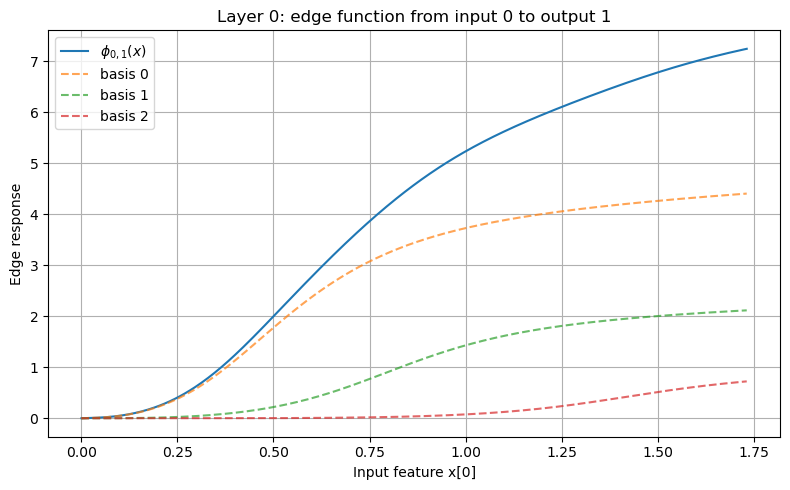

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out2_in0.mat


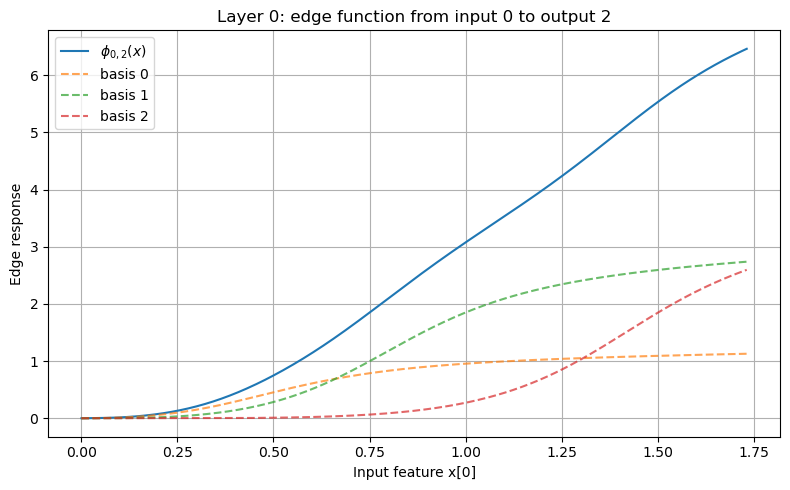

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out0_in1.mat


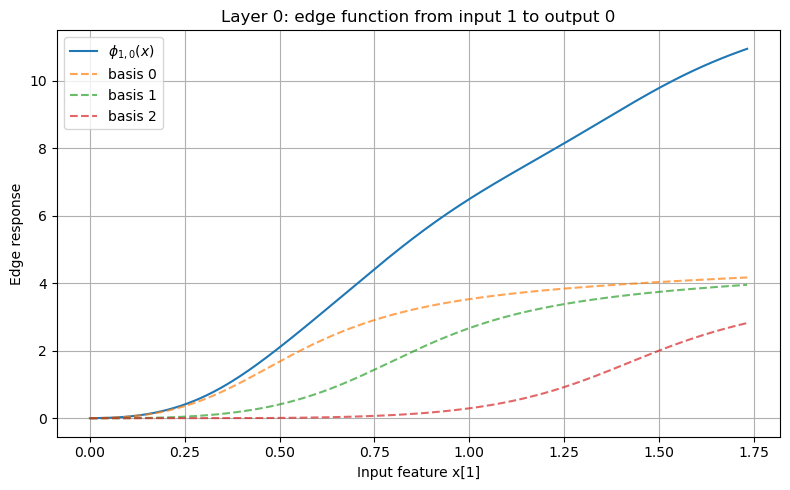

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out1_in1.mat


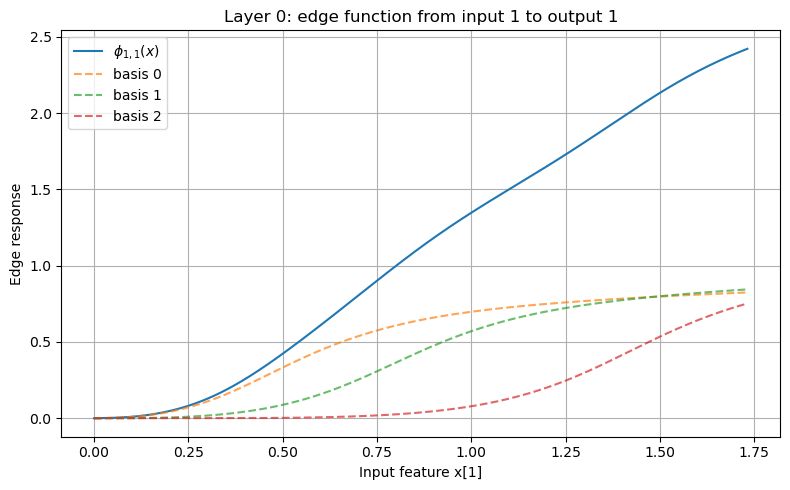

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out2_in1.mat


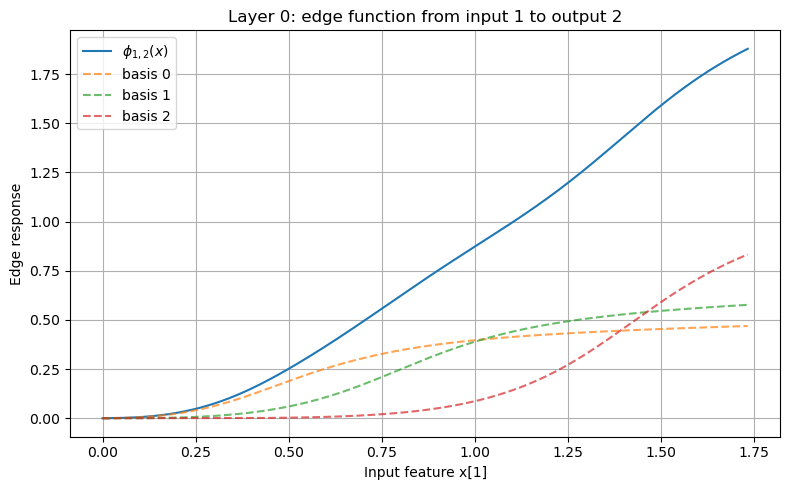

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out0_in2.mat


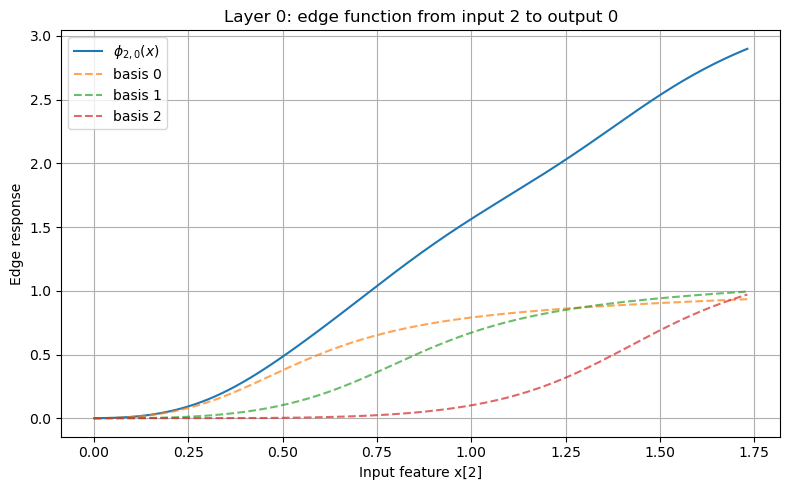

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out1_in2.mat


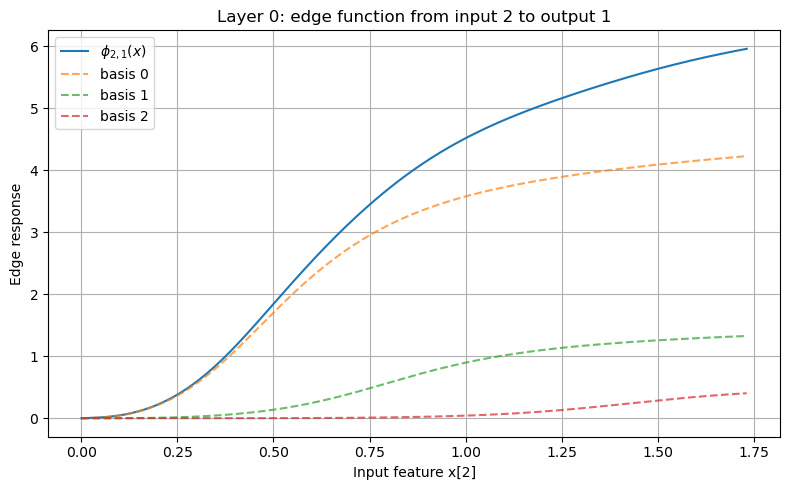

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out2_in2.mat


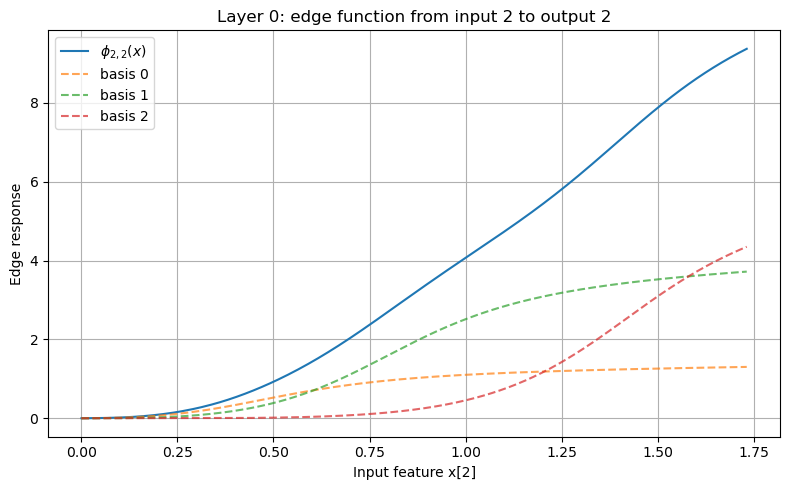

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out0_in3.mat


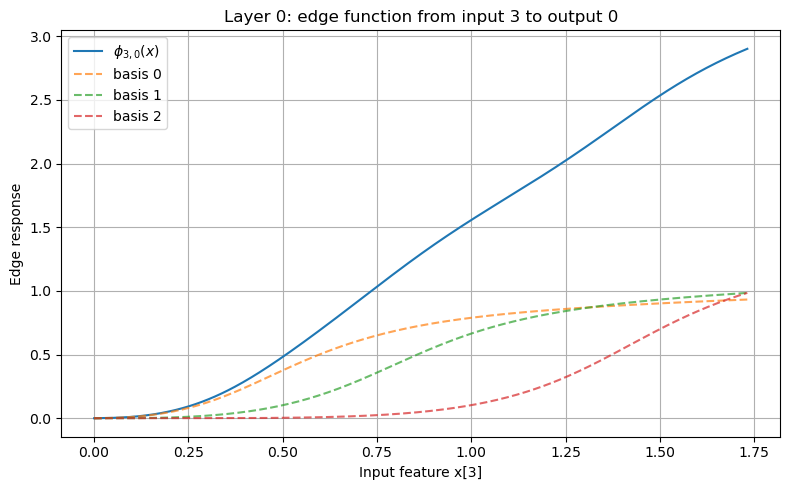

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out1_in3.mat


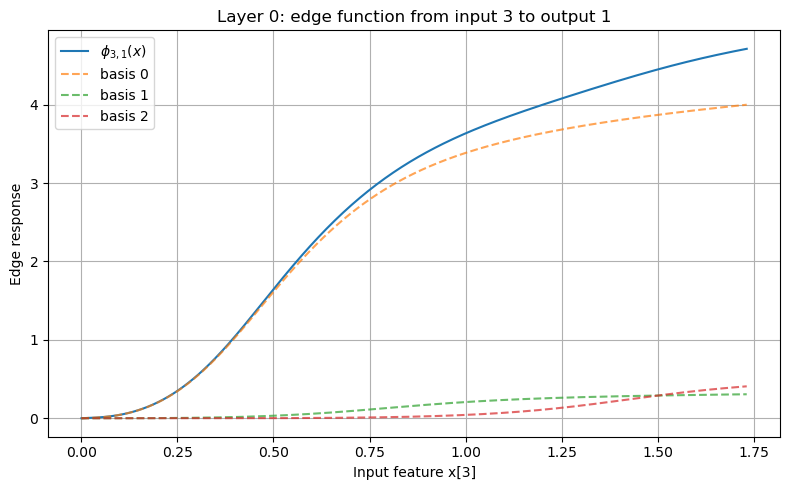

basis shape: torch.Size([400, 3])
basis finite: True
phi finite: True
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/edge_function_L0_out2_in3.mat


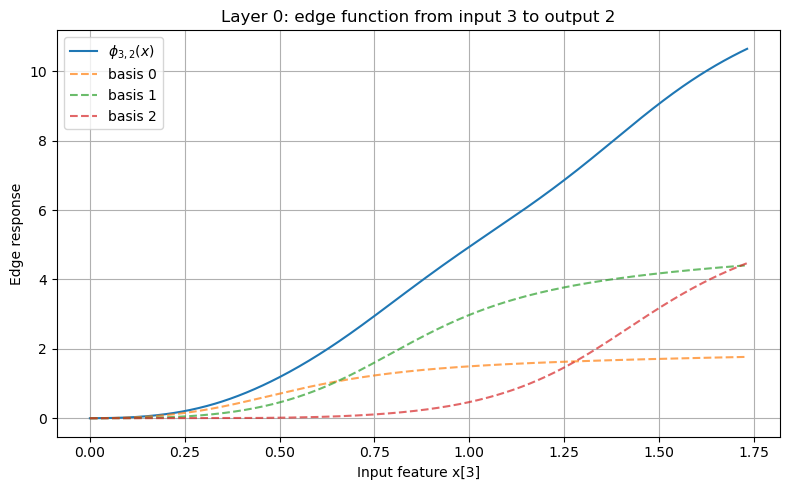

In [21]:
for in_idx in range(4):
    for out_idx in range(3):
        model.plot_edge_function(
            layer_idx=0, out_idx=out_idx, in_idx=in_idx,
            x_range=(x_min_physical, x_max_physical),
            show_basis=True,
            mat_export_path=f"edge_function_L0_out{out_idx}_in{in_idx}.mat",
            mat_export_dir=mat_folder,
        )

Input feature 0: sepal length (cm)
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/basis_functions_in0.mat


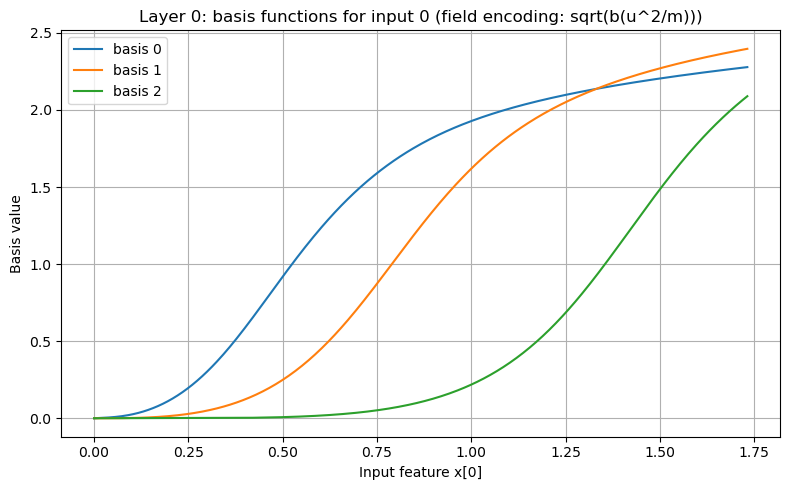

Input feature 1: sepal width (cm)
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/basis_functions_in1.mat


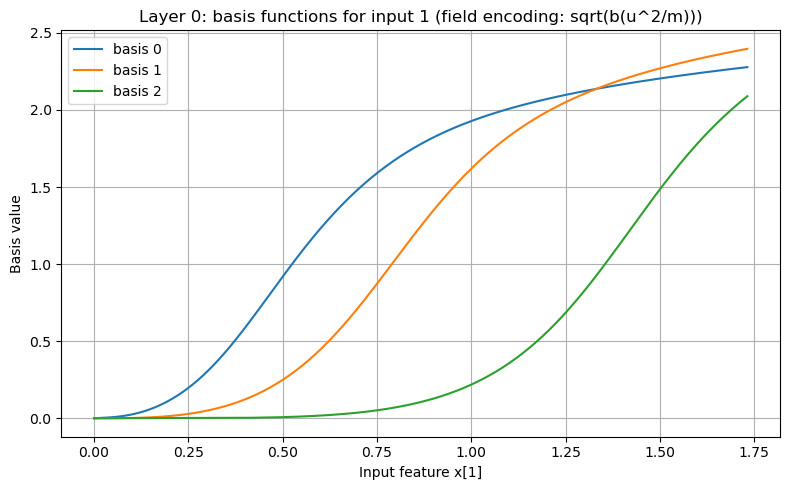

Input feature 2: petal length (cm)
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/basis_functions_in2.mat


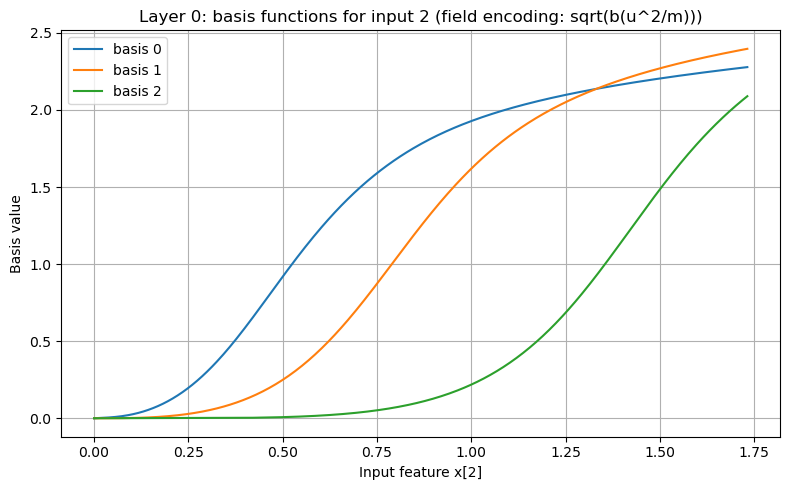

Input feature 3: petal width (cm)
Saved MATLAB plot data to: kan_iris_positive_sqrtm_export/basis_functions_in3.mat


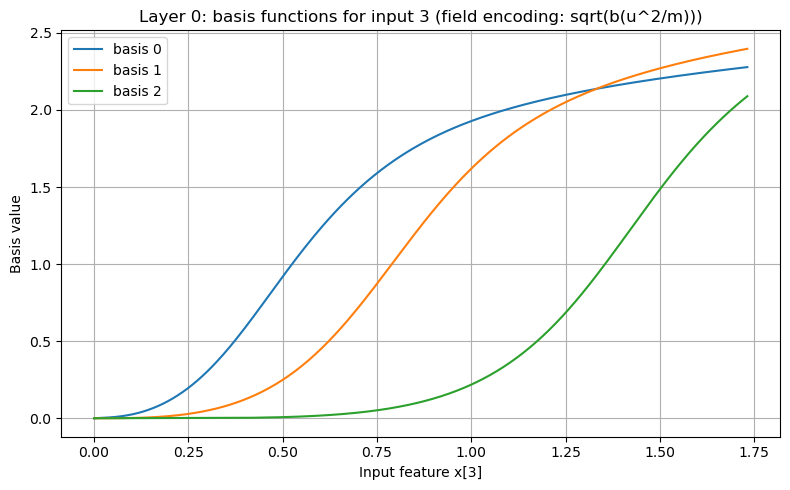

In [22]:
for in_idx, feature_name in enumerate(iris.feature_names):
    print(f"Input feature {in_idx}: {feature_name}")
    model.plot_basis_functions(
        layer_idx=0, in_idx=in_idx,
        x_range=(x_min_physical, x_max_physical),
        resolution=400,
        mat_export_path=f"basis_functions_in{in_idx}.mat",
        mat_export_dir=mat_folder,
    )

## Full forward pass export (MATLAB) and independent NumPy check

Every stage x → P → b → √b → a·√b → Σ for the test set, plus data, scaler and model metadata.

In [23]:
extra = {
    "model_description": "Direct photonic positive KAN for IRIS, field encoding: edge = sum_k a_k sqrt(b_k(x^2/m))",
    "dataset_name": "iris",
    "power_window": np.array([P_MIN, P_MAX]),
    "input_amplitude_range": np.array([x_min_physical, x_max_physical]),
    "selected_indices_python": selected_indices,
    "selected_indices_matlab": selected_indices + 1,
    "selected_detunings": set_detuning[selected_indices],
    "input_power": input_power, "peakout_data": peakout_data, "set_detuning": set_detuning,
    "scaler_feature_range": np.array(scaler.feature_range, dtype=float),
    "n_clipped_test": n_clipped_test,
    "scaler_data_min": scaler.data_min_, "scaler_data_max": scaler.data_max_,
    "scaler_scale": scaler.scale_, "scaler_min": scaler.min_,
    "X_train_original": X_train_original, "X_test_original": X_test_original,
    "X_train_scaled": X_train_scaled, "X_test_scaled": X_test_scaled,
    "y_train": y_train, "y_test": y_test,
    "train_pred": train_pred.cpu().numpy(), "test_pred": test_pred.cpu().numpy(),
    "train_accuracy": train_acc, "test_accuracy": test_acc,
    "confusion_matrix_test": confusion_matrix(y_test, test_pred.cpu().numpy()),
    "raw_coeffs": model.layers[0].raw_coeffs, "coeff_eps": model.layers[0].coeff_eps,
    "iris_feature_names": np.array(iris.feature_names, dtype=object),
    "iris_class_names": np.array(iris.target_names, dtype=object),
    "seed": SEED, "epochs": epochs, "lr": lr,
}

err = kan.export_full_forward_to_mat(
    model, X_test_t,
    os.path.join(mat_folder, "photonic_kan_iris_sqrtm_full_forward_test.mat"),
    extra=extra,
)
# The IRIS model runs in float32 (as in May), the NumPy check in float64. Near x = 0, b ~ 1e-8 ... 1e-12 and
# sqrt amplifies float32 rounding, so agreement is ~1e-5 relative (a float64 model agrees to ~1e-16).
assert err < 1e-4, "PyTorch and NumPy forward passes disagree"

Saved full forward pass to: kan_iris_positive_sqrtm_export/photonic_kan_iris_sqrtm_full_forward_test.mat
Max |PyTorch - NumPy| = 1.323e-04  (relative to max |y|: 6.242e-06)


## Comparison with the May (IPC 2026) result

In [24]:
old_path = os.path.join("results_v1_IPC2026", "kan_iris_positive_export", "final_predictions.mat")
if os.path.exists(old_path):
    old = loadmat(old_path, squeeze_me=True)
    old_acc = np.mean(old["test_pred"] == old["y_test"])
else:
    old_acc = 0.9737  # value reported in the abstract

print(f"{'':28s}{'May (b(x))':>14s}{'new (sqrt(b(x^2/m)))':>24s}")
print(f"{'Test accuracy':28s}{old_acc:>14.4f}{test_acc:>24.4f}")

                                May (b(x))    new (sqrt(b(x^2/m)))
Test accuracy                       0.9737                  0.9474
